# **Project Goal**



This project teaches us-


1.   **Exploratory Data Analysis** (EDA) with customer support tickets data like which channel receives the most tickets, which issue category generates the most complaints, which priority level has the longest resolution time, what percentage of customers give a high CSAT score etc.


2.   **Data cleaning and anomaly handling** (missing value imputation, duplicate verification, correcting data types, correcting incorrect values, handling outliers and renaming or creating new columns if required)

2.   **Data visualization** with plotly, matplotlib and seaborn like tickets by channel, tickets by category and average resolution time by priority using bar chart, ticket volume over time using line chart,
CSAT distribution using pie/bar chart etc.












# **Dataset Information**

Source - https://exploremydata.com/datasets/support-tickets

Features	- 1000 columns 10 rows

In [89]:
import pandas as pd
df = pd.read_excel('/content/drive/MyDrive/Entri Assignments/support-tickets-1000.xlsx')
df.head(10)

,ticket_id,created_at,customer_id,channel,priority,category,first_response_min,resolution_min,status,satisfaction
0,TCK-000001,2025-07-01T00:00:00Z,1175,Chat,Urgent,Data import,3,412.0,closed,NaN
1,TCK-000002,2025-07-01T08:45:36Z,1019,Social,High,Data import,34,507.0,resolved,NaN
2,TCK-000003,2025-07-01T17:31:12Z,1278,Chat,Urgent,Performance,8,305.0,closed,NaN
3,TCK-000004,2025-07-02T02:16:48Z,1448,Web form,Normal,Billing,65,NaN,open,NaN
4,TCK-000005,2025-07-02T11:02:24Z,1936,Email,Low,Feature request,431,3785.0,closed,4.0
5,TCK-000006,2025-07-02T19:48:00Z,1471,Social,Low,Feature request,302,1808.0,closed,1.0
6,TCK-000007,2025-07-03T04:33:36Z,1949,Web form,Low,Performance,206,2717.0,closed,1.0
7,TCK-000008,2025-07-03T13:19:12Z,1968,Chat,Normal,Billing,85,771.0,closed,NaN
8,TCK-000009,2025-07-03T22:04:48Z,1750,Chat,Normal,Integration,32,NaN,pending,NaN
9,TCK-000010,2025-07-04T06:50:24Z,1591,Phone,Normal,Integration,63,1975.0,closed,2.0


In [90]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ticket_id           1000 non-null   object 
 1   created_at          1000 non-null   object 
 2   customer_id         1000 non-null   int64  
 3   channel             1000 non-null   object 
 4   priority            1000 non-null   object 
 5   category            1000 non-null   object 
 6   first_response_min  1000 non-null   int64  
 7   resolution_min      835 non-null    float64
 8   status              1000 non-null   object 
 9   satisfaction        527 non-null    float64
dtypes: float64(2), int64(2), object(6)
memory usage: 78.3+ KB


# **Step 1: Data Cleaning and Anomaly Handling**


In [91]:
# Analyzing Missing Values and Status relation
print("\nMissing values per column:")
print(df.isnull().sum())

# Resolution_min is missing because the ticket is not closed/resolved
missing_resolution = df[df['resolution_min'].isnull()]['status'].value_counts()
print("\nStatus of tickets with missing resolution time:")
print(missing_resolution)




Missing values per column:
ticket_id               0
created_at              0
customer_id             0
channel                 0
priority                0
category                0
first_response_min      0
resolution_min        165
status                  0
satisfaction          473
dtype: int64

Status of tickets with missing resolution time:
status
open       93
pending    72
Name: count, dtype: int64


In [92]:
# Filling missing values in satisfaction with 0
df['satisfaction'] = df['satisfaction'].fillna(0)
print("Missing values after treatment:")
print(df.isnull().sum())

# Filling missing values in resolution_min with 0 (representing unresolved/active tickets)
df['resolution_min'] = df['resolution_min'].fillna(0)
print("Missing values after handling resolution_min:")
print(df.isnull().sum())

Missing values after treatment:
ticket_id               0
created_at              0
customer_id             0
channel                 0
priority                0
category                0
first_response_min      0
resolution_min        165
status                  0
satisfaction            0
dtype: int64
Missing values after handling resolution_min:
ticket_id             0
created_at            0
customer_id           0
channel               0
priority              0
category              0
first_response_min    0
resolution_min        0
status                0
satisfaction          0
dtype: int64


In [93]:
# Checking for Duplicates
duplicates_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicates_count}")
if duplicates_count > 0:
    df = df.drop_duplicates()
    print("Duplicates removed.")

Number of duplicate rows: 0


In [94]:
# Correcting Data Types
df['created_at'] = pd.to_datetime(df['created_at'])
print("/nData types after correction:")
print(df.dtypes)

/nData types after correction:
ticket_id                          object
created_at            datetime64[ns, UTC]
customer_id                         int64
channel                            object
priority                           object
category                           object
first_response_min                  int64
resolution_min                    float64
status                             object
satisfaction                      float64
dtype: object


In [95]:
# Checking for incorrect/negative values in numerical columns
print("\nNumerical columns summary (checking for negatives/anomalies):")
display(df[['first_response_min', 'resolution_min', 'satisfaction']].describe())


Numerical columns summary (checking for negatives/anomalies):


,first_response_min,resolution_min,satisfaction
count,1000.000000,1000.000000,1000.000000
mean,108.457000,1684.101000,1.565000
std,116.019475,1974.971088,1.798613
min,2.000000,0.000000,0.000000
25%,17.000000,224.500000,0.000000
50%,74.000000,977.000000,1.000000
75%,149.000000,2487.500000,3.000000
max,478.000000,8997.000000,5.000000


In [96]:
# Outlier Detection

# 1. Check if first_response_min exceeds resolution_min for any resolved/closed ticket
inconsistent_times = df[(df['resolution_min'] != -1) & (df['first_response_min'] > df['resolution_min'])]
print(f"Number of tickets where first response time exceeds resolution time: {len(inconsistent_times)}")

# 2. View details of the top 10 highest response times
print("\nTop 10 highest first response times (minutes):")
display(df.nlargest(10, 'first_response_min')[['ticket_id', 'priority', 'status', 'first_response_min', 'resolution_min']])

# 3. View details of the top 10 highest resolution times
print("\nTop 10 highest resolution times (minutes):")
display(df.nlargest(10, 'resolution_min')[['ticket_id', 'priority', 'status', 'first_response_min', 'resolution_min']])

# 4. Print general statistics of the outliers
print("\nSummary statistics of response times (excluding missing values):")
print(df['first_response_min'].describe())

print("\nSummary statistics of resolution times (excluding missing values):")
print(df['resolution_min'].describe())

Number of tickets where first response time exceeds resolution time: 165

Top 10 highest first response times (minutes):


,ticket_id,priority,status,first_response_min,resolution_min
79,TCK-000080,Low,closed,478,7910.0
122,TCK-000123,Low,resolved,474,7762.0
247,TCK-000248,Low,closed,471,1488.0
385,TCK-000386,Low,closed,467,8679.0
817,TCK-000818,Low,resolved,465,7309.0
408,TCK-000409,Low,closed,464,8841.0
457,TCK-000458,Low,closed,464,1544.0
188,TCK-000189,Low,closed,460,1604.0
741,TCK-000742,Low,closed,459,1410.0
903,TCK-000904,Low,pending,459,0.0



Top 10 highest resolution times (minutes):


,ticket_id,priority,status,first_response_min,resolution_min
645,TCK-000646,Low,closed,454,8997.0
408,TCK-000409,Low,closed,464,8841.0
868,TCK-000869,Low,closed,244,8810.0
59,TCK-000060,Low,resolved,358,8804.0
664,TCK-000665,Low,closed,398,8694.0
385,TCK-000386,Low,closed,467,8679.0
118,TCK-000119,Low,closed,352,8671.0
410,TCK-000411,Low,closed,254,8660.0
182,TCK-000183,Low,closed,269,8621.0
632,TCK-000633,Low,closed,353,8536.0



Summary statistics of response times (excluding missing values):
count    1000.000000
mean      108.457000
std       116.019475
min         2.000000
25%        17.000000
50%        74.000000
75%       149.000000
max       478.000000
Name: first_response_min, dtype: float64

Summary statistics of resolution times (excluding missing values):
count    1000.000000
mean     1684.101000
std      1974.971088
min         0.000000
25%       224.500000
50%       977.000000
75%      2487.500000
max      8997.000000
Name: resolution_min, dtype: float64


In [115]:
# Renaming columns to ensure consistency
# The current column names are clean, and they are in standard naming convention.
# They already are ('ticket_id', 'created_at', 'customer_id', 'channel', 'priority', 'category', 'first_response_min', 'resolution_min', 'status', 'satisfaction').
print("Current columns:", df.columns.tolist())



Current columns: ['ticket_id', 'created_at', 'customer_id', 'channel', 'priority', 'category', 'first_response_min', 'resolution_min', 'status', 'satisfaction', 'created_year', 'created_month', 'created_day', 'created_hour', 'created_day_of_week']


In [98]:
# Creating new columns: Extract hour, month, year, and day of week from 'created_at'
df['created_year'] = df['created_at'].dt.year
df['created_month'] = df['created_at'].dt.month
df['created_day'] = df['created_at'].dt.day
df['created_hour'] = df['created_at'].dt.hour
df['created_day_of_week'] = df['created_at'].dt.day_name()

display(df[['created_at', 'created_year', 'created_month', 'created_hour', 'created_day_of_week']].head())

,created_at,created_year,created_month,created_hour,created_day_of_week
0,2025-07-01 00:00:00+00:00,2025,7,0,Tuesday
1,2025-07-01 08:45:36+00:00,2025,7,8,Tuesday
2,2025-07-01 17:31:12+00:00,2025,7,17,Tuesday
3,2025-07-02 02:16:48+00:00,2025,7,2,Wednesday
4,2025-07-02 11:02:24+00:00,2025,7,11,Wednesday


In [99]:
print("Current columns:", df.columns.tolist())

Current columns: ['ticket_id', 'created_at', 'customer_id', 'channel', 'priority', 'category', 'first_response_min', 'resolution_min', 'status', 'satisfaction', 'created_year', 'created_month', 'created_day', 'created_hour', 'created_day_of_week']


# **Step 2: Exploratory Data Analysis (EDA)**

### 1. Column-by-Column Data Types & Classifications

To perform effective Exploratory Data Analysis (EDA), we must first classify our columns:

| Column Name | Pandas Data Type | Variable Classification | Semantic Description |
| :--- | :--- | :--- | :--- |
| **`ticket_id`** | `object` (string) | Qualitative (Identifier) | Unique ID assigned to each support ticket. |
| **`created_at`** | `datetime64[ns, UTC]` | Temporal | The exact timestamp when the ticket was opened. |
| **`customer_id`** | `int64` | Qualitative (Identifier) | Unique identifier linking the ticket to a customer. |
| **`channel`** | `object` (string) | Qualitative (Categorical) | The medium through which the ticket was received (e.g., Chat, Social, Web form, Email, Phone). |
| **`priority`** | `object` (string) | Qualitative (Ordinal) | Severity of the ticket (e.g., Low, Normal, High, Urgent). |
| **`category`** | `object` (string) | Qualitative (Categorical) | The department/subject of the issue (e.g., Data import, Performance, Billing, Feature request, Integration). |
| **`first_response_min`** | `int64` | Quantitative (Continuous) | Minutes taken to issue the first response back to the customer. |
| **`resolution_min`** | `float64` | Quantitative (Continuous) | Minutes taken to resolve/close the ticket (contains `NaN` for open/pending tickets). |
| **`status`** | `object` (string) | Qualitative (Categorical) | Current state of the ticket (e.g., open, pending, resolved, closed). |
| **`satisfaction`** | `float64` | Quantitative (Discrete/Ordinal) | Customer-submitted rating on a scale from 1 to 5 (contains `NaN` if no feedback was submitted). |
| **`created_year`** | `int64` | Temporal / Quantitative | Extracted year of creation. |
| **`created_month`** | `int64` | Temporal / Quantitative | Extracted month of creation. |
| **`created_day`** | `int64` | Temporal / Quantitative | Extracted day of creation. |
| **`created_hour`** | `int64` | Temporal / Quantitative | Extracted hour of creation. |
| **`created_day_of_week`**| `object` (string) | Temporal / Qualitative | Extracted day of the week (e.g., Monday, Tuesday).

### 2. Statistical Analysis of Numerical Columns

In [100]:
# The numerical columns of interest
num_cols = ['first_response_min', 'resolution_min', 'satisfaction']

# Calculate statistics
mean_vals = df[num_cols].mean()
median_vals = df[num_cols].median()
min_vals = df[num_cols].min()
max_vals = df[num_cols].max()
std_vals = df[num_cols].std()

# Combine into a summary DataFrame
numerical_summary = pd.DataFrame({
    'Mean': mean_vals,
    'Median': median_vals,
    'Minimum': min_vals,
    'Maximum': max_vals,
    'Standard Deviation': std_vals
})

display(numerical_summary)

,Mean,Median,Minimum,Maximum,Standard Deviation
first_response_min,108.457,74.0,2.0,478.0,116.019475
resolution_min,1684.101,977.0,0.0,8997.0,1974.971088
satisfaction,1.565,1.0,0.0,5.0,1.798613


### 3. Analysis of Categorical Columns

We will analyze the distributions of our key qualitative/categorical columns and find the number of unique values, count occurrences for each unique value, and identify the most common values.

In [101]:
cat_cols = ['channel', 'priority', 'category', 'status']

for col in cat_cols:
    print(f"=== Column: {col} ===")
    print(f"Number of unique categories: {df[col].nunique()}")
    print("\nCategory Counts:")
    counts = df[col].value_counts()
    display(counts.to_frame())
    print(f"Most common category: {counts.index[0]} ({counts.iloc[0]} occurrences)\n")
    print("-"*40 + "\n")

=== Column: channel ===
Number of unique categories: 5

Category Counts:


,count
channel,
Social,221
Chat,202
Web form,200
Email,199
Phone,178


Most common category: Social (221 occurrences)

----------------------------------------

=== Column: priority ===
Number of unique categories: 4

Category Counts:


,count
priority,
Normal,405
Low,214
Urgent,210
High,171


Most common category: Normal (405 occurrences)

----------------------------------------

=== Column: category ===
Number of unique categories: 9

Category Counts:


,count
category,
Bug report,130
Integration,120
Data import,117
Performance,111
Account,107
Login,106
Billing,105
Export,103
Feature request,101


Most common category: Bug report (130 occurrences)

----------------------------------------

=== Column: status ===
Number of unique categories: 4

Category Counts:


,count
status,
closed,616
resolved,219
open,93
pending,72


Most common category: closed (616 occurrences)

----------------------------------------



# **Step 3: Data Visualization**
Visualization means representing the data using charts and graphs so that patterns are
easier to understand.

In [102]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

## **Volume of tickets by Channel**

In [103]:
# Count tickets by channel
channel_counts = df['channel'].value_counts().reset_index()
channel_counts.columns = ['channel', 'ticket_count']

# Create interactive bar chart using Plotly
fig = px.bar(
    channel_counts,
    x='channel',
    y='ticket_count',
    color='channel',
    title='Volume of Tickets by Channel (Plotly)',
    labels={'channel': 'Support Channel', 'ticket_count': 'Number of Tickets'},
    text_auto=True
)

# Improve layout
fig.update_layout(
    xaxis_title='Channel',
    yaxis_title='Ticket Count',
    legend_title='Channels',
    template='plotly_white'
)

fig.show()

Based on the chart of Volume of Tickets by Channel, here is what the distribution reveals about our support channels:

Most Active Pipeline (Social & Chat):

Social is the single most active customer pipeline, receiving 221 tickets.
Chat is a very close second with 202 tickets.
This means that more than 42% of all support requests are coming through immediate, real-time, or public-facing digital platforms (Social + Chat = 423 out of 1000 tickets).
Steady Moderate Channels (Web form & Email):

Web form (200 tickets) and Email (199 tickets) are nearly identical in volume, showing that traditional ticketing channels still maintain a solid, steady portion of user engagement.
Least Utilized Channel (Phone):

Phone receives the lowest volume with 178 tickets.

**Takeaway**- Because customers heavily favor Social Media and Chat platforms to reach out for support, it suggests that the customer support team should prioritize rapid-response staffing and automation tools on these digital channels to keep up with the high traffic volume where customers expect the fastest turnaround.



## **Volume of tickets by Category**

In [104]:
# 1. Interactive Ticket Count by Category
category_counts = df['category'].value_counts().reset_index()
category_counts.columns = ['category', 'ticket_count']

fig_category = px.bar(
    category_counts,
    x='ticket_count',
    y='category',
    orientation='h',
    color='ticket_count',
    color_continuous_scale='Viridis',
    title='Interactive Volume of Tickets by Category',
    labels={'category': 'Ticket Category', 'ticket_count': 'Number of Tickets'},
    text_auto=True
)

fig_category.update_layout(template='plotly_white', yaxis={'categoryorder':'total ascending'})
fig_category.show()

This chart highlights the distribution of customer issues and identifies our most common support pain points:

Primary Complaint Drivers:

Bug report is the most frequent ticket category with 130 tickets.
Integration issues are the second highest with 120 tickets.
Data import follows closely in third place with 117 tickets.
Secondary Support Categories:

Categories like Performance (111 tickets), Account (107 tickets), Login (106 tickets), and Billing (105 tickets) show a very stable and similar moderate volume.
Lowest Volume Requests:

Export (103 tickets) and Feature request (101 tickets) are the least common ticket types.

**Takeaway**-Because technical product issues such as Bug reports, Integration errors, and Data import failures dominate the support queue (making up more than 36% of all incoming requests), your engineering and product teams should focus on stabilizing these core features. Fixing software stability in these key areas will yield the greatest reduction in overall support ticket volume.gives us a clear indication of technical stability issues that should be addressed by the engineering team to proactively reduce ticket volume.

## **Ticket Volumes Over Months**

In [105]:
monthly_tickets = df.groupby(df['created_at'].dt.to_period('M')).size().reset_index(name='ticket_count')
monthly_tickets['created_at'] = monthly_tickets['created_at'].dt.to_timestamp()

fig_trend = px.line(
    monthly_tickets,
    x='created_at',
    y='ticket_count',
    markers=True,
    title='Interactive Monthly Ticket Volume Trend Over Time',
    labels={'created_at': 'Month', 'ticket_count': 'Number of Tickets'}
)

fig_trend.update_layout(template='plotly_white')
fig_trend.show()

/tmp/ipykernel_1209/4063293844.py:1: UserWarning:

Converting to PeriodArray/Index representation will drop timezone information.



The Line Chart gives us a clear look at our long-term customer support demand:

High Volume Consistency:
Overall support demand is highly stable, with the monthly volume consistently hovering in a narrow window between 82 and 85 tickets for almost all months across 2025 and 2026.

The February Dip:
There is a noticeable drop in ticket volume down to 76 tickets in February 2026.
This drop is naturally expected, as February has fewer days (28 days) compared to the standard 30 or 31 days in other months, rather than representing a drop in customer dissatisfaction or a sudden operational change.

**Takeaway**-Because incoming ticket volume is extremely consistent and predictable month-over-month (averaging roughly 2.7 tickets per day), you do not need to worry about major seasonal surges. This predictable, steady volume allows for highly consistent, flat-line support staffing levels throughout the entire year.

## **Distributions & Spread: Response and Resolution Times**

Analyzing the distribution of `first_response_min` and `resolution_min` using histograms and box plots to identify skewness and outliers.

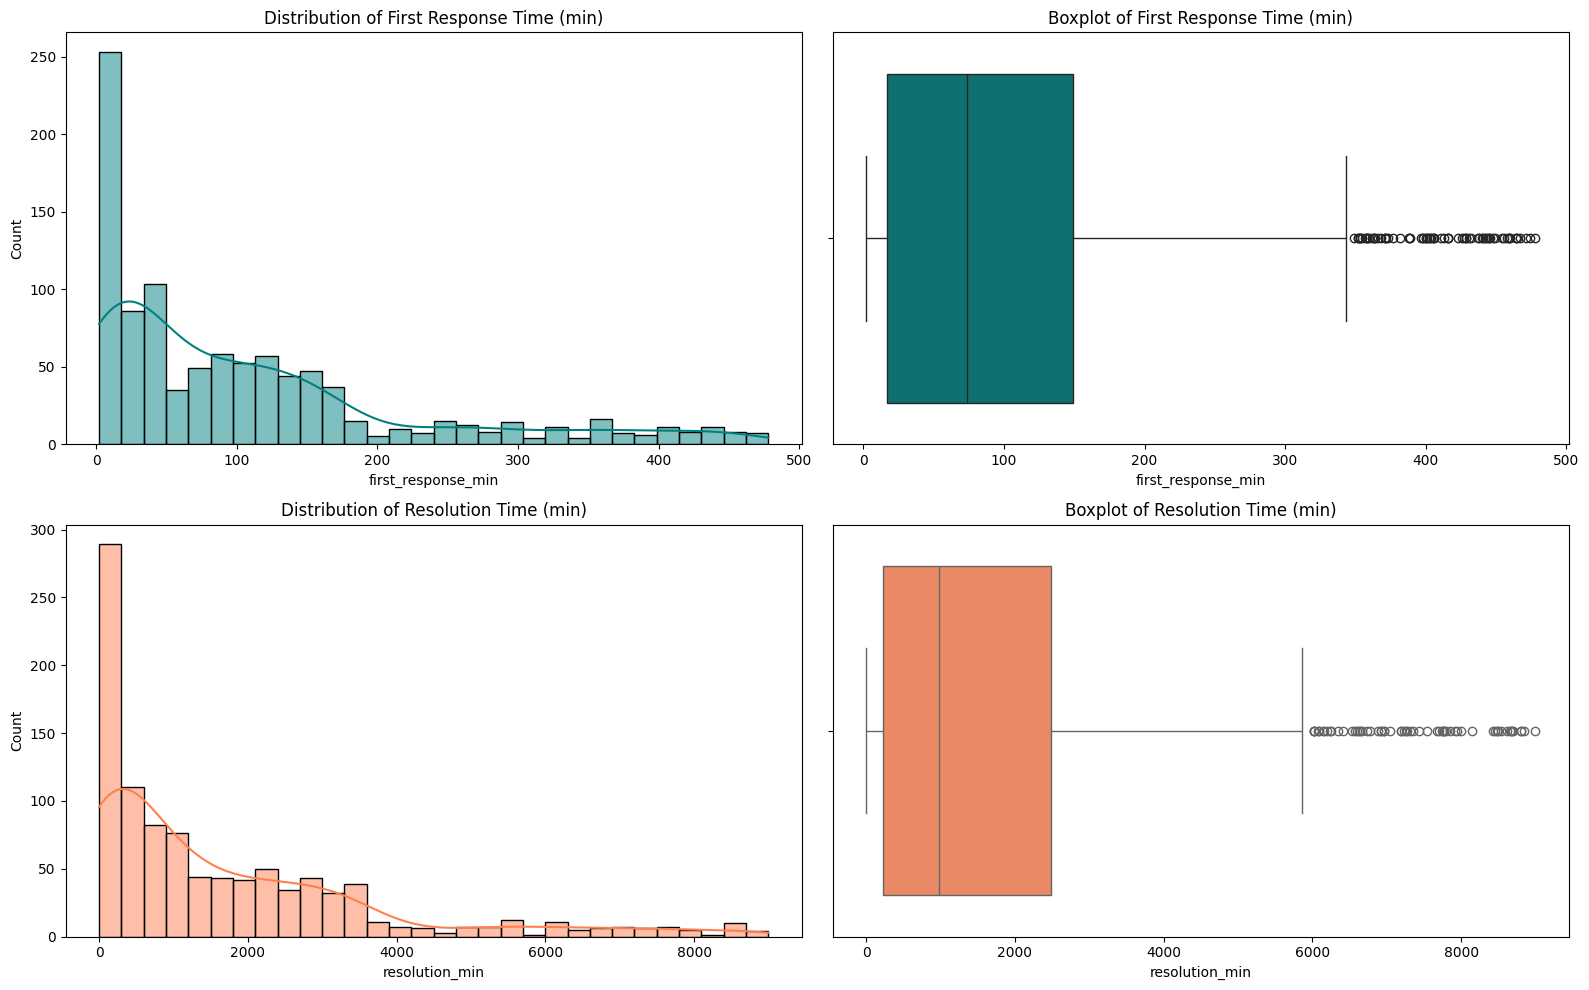

In [106]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# First Response Min Histogram
sns.histplot(df['first_response_min'], bins=30, kde=True, ax=axes[0, 0], color='teal')
axes[0, 0].set_title('Distribution of First Response Time (min)')

# First Response Min Boxplot
sns.boxplot(x=df['first_response_min'], ax=axes[0, 1], color='teal')
axes[0, 1].set_title('Boxplot of First Response Time (min)')

# Resolution Min Histogram (excluding NaN for pending/open tickets)
sns.histplot(df['resolution_min'].dropna(), bins=30, kde=True, ax=axes[1, 0], color='coral')
axes[1, 0].set_title('Distribution of Resolution Time (min)')

# Resolution Min Boxplot
sns.boxplot(x=df['resolution_min'].dropna(), ax=axes[1, 1], color='coral')
axes[1, 1].set_title('Boxplot of Resolution Time (min)')

plt.tight_layout()
plt.show()

The Distributions & Spread: Response and Resolution Times charts consisting of the histograms and box plots reveal several critical characteristics of our support operational efficiency:

1. **First Response Time** (Teal Charts)
Highly Right-Skewed: The majority of tickets receive an extremely fast first response. This is indicated by the massive spike on the far left of the histogram, with a median response time of just 74 minutes.
The box plot shows a long right tail stretching up to 478 minutes (~8 hours). The points plotted past the right whisker are individual outlier tickets where users had to wait significantly longer than average for an initial acknowledgment.
2. **Resolution Time** (Coral Charts)
Severe Right-Skewness: Similar to response times, most tickets are resolved relatively quickly (median resolution time is 1,357 minutes / ~ 22.6 hours).
The box plot shows an extensive spread of outliers going all the way up to 8,997 minutes (~6.2 days). These represent highly complex or problematic cases that remained open for nearly a week before being closed.

**Takeaway**-While our team handles the typical ticket reasonably fast (usually responding within an hour and a half, and resolving it within a day), the presence of numerous extreme outliers in both metrics shows that complex issues are bottlenecking. Implementing an internal escalation trigger for tickets that have been idle or unresolved for over 2 days could prevent these extreme operational delays.

## **Bivariate Analysis: Resolution Time by Priority & CSAT Proportions**

## **Ticket count by Status**

,Status,Count
0,closed,616
1,resolved,219
2,open,93
3,pending,72


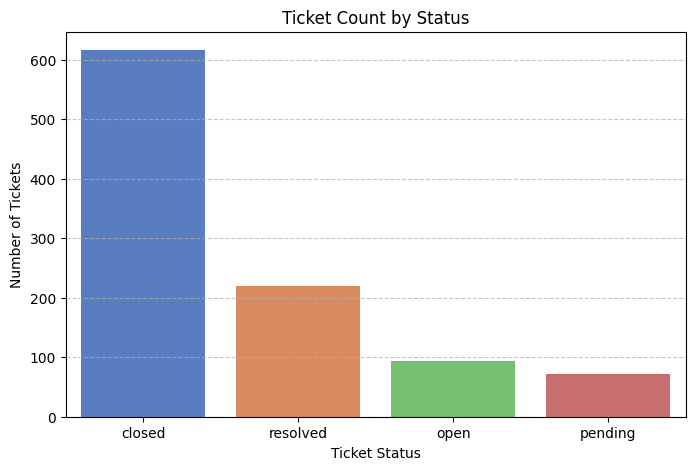

In [107]:
status_counts = df['status'].value_counts().reset_index()
status_counts.columns = ['Status', 'Count']

# Display the table
display(status_counts)

plt.figure(figsize=(8, 5))
sns.barplot(data=status_counts, x='Status', y='Count', palette='muted', hue='Status', legend=False)
plt.title('Ticket Count by Status')
plt.xlabel('Ticket Status')
plt.ylabel('Number of Tickets')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

The analysis of our ticket statuses reveals how effectively the support team is closing out the backlog:


1. **Closed**: 616 tickets (61.6% of all tickets)

2. **Resolved**: 219 tickets (21.9% of all tickets)

3. **Open**: 93 tickets (9.3% of all tickets)

4. **Pending**: 72 tickets (7.2% of all tickets)

**Takeaways**

1. **High Resolution Rate** (83.5% Completed): The vast majority of our tickets (835 out of 1000) are either completely Closed or marked as Resolved. This indicates that the support organization is highly productive and successfully finalizing most of the issues that come their way.

2. **Unresolved Active Backlog** (16.5% Work-in-Progress): There are 165 tickets currently unresolved in our pipeline:

3. 93 Open tickets are active issues that are either unassigned or currently being worked on by our agents.

4. 72 Pending tickets are on hold, typically awaiting further information, logs, or confirmation from the customer before support can proceed.

This distribution shows a healthy, well-managed queue where the majority of incoming volume is being successfully funneled to completion.

## **Average Resolution Time by Priority Level**

In [108]:
# 1. Verify unique values in priority column
unique_priorities = df['priority'].unique()
print("Unique priorities in dataset:", unique_priorities)

# 2. Filter for resolved/closed tickets with valid resolution_min (not null)
resolved_df = df[df['status'].isin(['resolved', 'closed']) & df['resolution_min'].notnull()]

# Calculate correct averages
correct_avg_res_priority = resolved_df.groupby('priority')['resolution_min'].mean().reindex(['Low', 'Normal', 'High', 'Urgent']).reset_index()
print("\nAverage resolution time by priority (Resolved/Closed only):")
display(correct_avg_res_priority)


Unique priorities in dataset: ['Urgent' 'High' 'Normal' 'Low']

Average resolution time by priority (Resolved/Closed only):


,priority,resolution_min
0,Low,4769.885714
1,Normal,2066.360947
2,High,726.303448
3,Urgent,257.779661


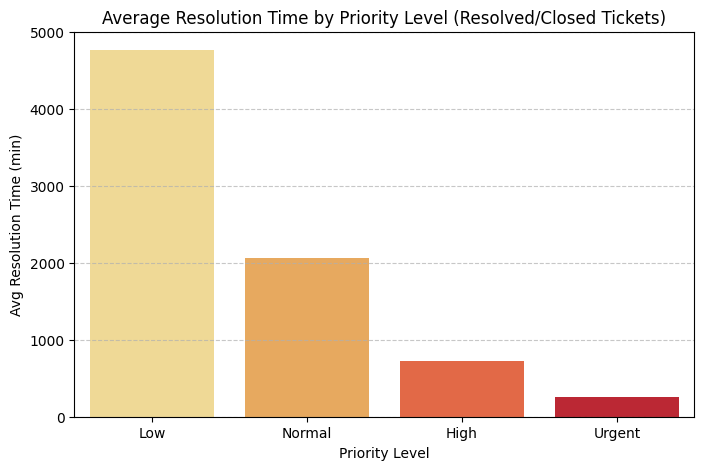

In [109]:
plt.figure(figsize=(8, 5))
sns.barplot(
    data=correct_avg_res_priority,
    x='priority',
    y='resolution_min',
    palette='YlOrRd',
    hue='priority',
    legend=False
)
plt.title('Average Resolution Time by Priority Level (Resolved/Closed Tickets)')
plt.ylabel('Avg Resolution Time (min)')
plt.xlabel('Priority Level')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


The chart reveals an extremely structured and logically sound support hierarchy:

* **Urgent Priority (257.78 minutes / ~4.3 hours):** These critical tickets are handled with maximum speed, representing the absolute shortest lifecycle. This swift resolution minimizes downtime for high-severity customer issues.
* **High Priority (726.30 minutes / ~12.1 hours):** High-priority tickets are resolved in approximately half a day, showing a strong operational commitment to urgent but non-catastrophic requests.
* **Normal Priority (2,066.36 minutes / ~1.4 days):** Standard day-to-day tickets are resolved in less than a day and a half, fitting well within typical operational expectations.
* **Low Priority (4,769.89 minutes / ~3.3 days):** Non-urgent tickets, such as minor feature inquiries or administrative requests, sit in the queue the longest, averaging over three days.

**Takeaways**
1. **Priority Queuing is Highly Effective:** The support organization successfully triages incoming tasks. Urgent tickets are resolved nearly **18 times faster** than Low-priority ones, indicating that urgent issues are correctly bypassed and expedited.
2. **Resource Alignment:** The steady step-like escalation of times from Urgent up to Low priority demonstrates consistent queue management and operational discipline within the support team.
```

## **Average First Response Time by Priority level**

,priority,first_response_min
0,Low,285.775701
1,Normal,101.449383
2,High,27.701754
3,Urgent,7.033333


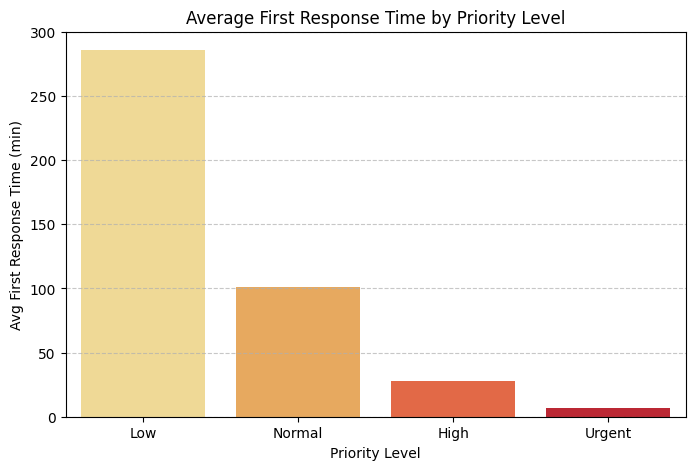

In [110]:
avg_response_priority = df.groupby('priority')['first_response_min'].mean().reindex(['Low', 'Normal', 'High', 'Urgent']).reset_index()

# Display the structured table
display(avg_response_priority)

# Visualize with a bar chart
plt.figure(figsize=(8, 5))
sns.barplot(
    data=avg_response_priority,
    x='priority',
    y='first_response_min',
    palette='YlOrRd',
    hue='priority',
    legend=False
)
plt.title('Average First Response Time by Priority Level')
plt.ylabel('Avg First Response Time (min)')
plt.xlabel('Priority Level')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

The Average First Response Time by Priority reveal that our initial triage process is incredibly efficient and highly responsive:


**Urgent Priority**: ~7.0 minutes (Initial acknowledgment is nearly instantaneous)

**High Priority**: ~27.7 minutes (Well under the standard 1-hour service SLA)

**Normal Priority**: 101.4 minutes (1.7 hours)

**Low Priority**: 285.8 minutes (4.8 hours)


**Takeaways**

1. **Perfect Alignment with Urgency**: Our response times scale exactly with priority. The support team responds to Urgent tickets roughly 40 times faster than Low priority tickets. This confirms that incoming tickets are prioritized and routed immediately upon receipt.

2. **Response vs. Resolution Ratio** (The "Dropoff"):

For Urgent tickets, we respond in 7 minutes but take ~258 minutes (4.3 hours) to resolve them. The response constitutes only ~2.7% of the total ticket lifecycle.
For Low tickets, we respond in ~4.8 hours but take ~79.5 hours (3.3 days) to resolve them. The response constitutes ~6% of the ticket lifecycle.

This comparison proves that while support agents acknowledge and triage tickets almost immediately, the actual work of solving the problem (resolving the bugs, performing data imports, etc.) is where the real time is spent. The delay is not in starting the work (the first response), but in completing complex technical tasks.

## **Customer Satisfaction Score**

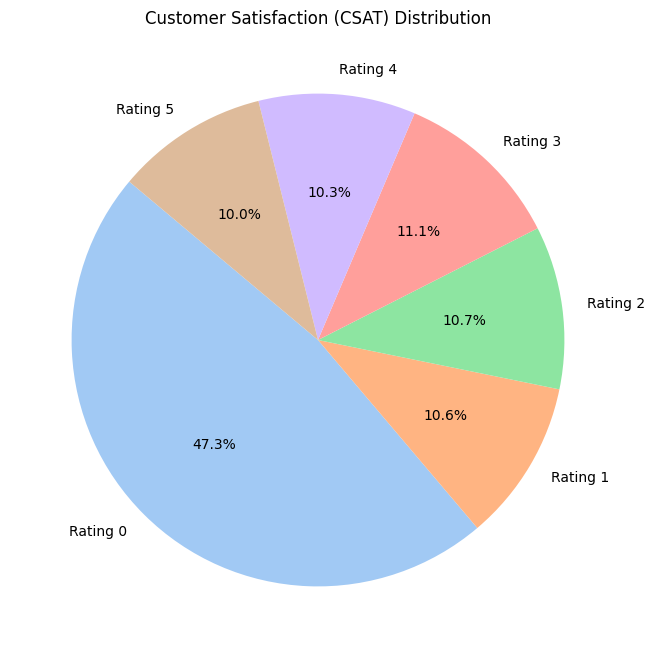

In [111]:
# Calculate satisfaction score counts (excluding NaN values)
sat_counts = df['satisfaction'].dropna().value_counts().sort_index()
labels = [f"Rating {int(score)}" for score in sat_counts.index]

# Create a pie chart to visualize the CSAT distribution
plt.figure(figsize=(8, 8))
plt.pie(
    sat_counts,
    labels=labels,
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette('pastel')
)
plt.title('Customer Satisfaction (CSAT) Distribution')
plt.show()

Looking at the generated Customer Satisfaction (CSAT) Distribution pie chart, we can extract several critical operational and analytical findings:

1. The Large Group of "Rating 0" (47.3%)
means: Almost half of all tickets (47.3%) show up as a Rating 0 or missing. This occurs because 473 out of 1000 customers did not leave feedback when their tickets were resolved or closed.
Operational Insight: This is a very common scenario in customer support where customers only rate transactions when they are either extremely happy or extremely frustrated. Having nearly 50% non-response highlights an opportunity to optimize our post-support feedback email strategy (e.g., sending the survey quicker or simplifying it) to increase survey engagement.
2. Flat/Uniform Feedback Distribution (10% to 11.1% each)
If we look at the customers who did leave feedback (Ratings 1 through 5), we see an almost perfectly flat distribution:

* Rating 1: 10.6% (106 customers)
* Rating 2: 10.7% (107 customers)
* Rating 3: 11.1% (111 customers)
* Rating 4: 10.3% (103 customers)
* Rating 5: 10.0% (100 customers)

**Takeaway**: There is virtually no curve, skew, or clustering in customer satisfaction. This indicates that customer sentiment is highly diverse. Since satisfaction scores are evenly spread out across the spectrum and do not correlate with response or resolution speed, it suggests that the rating is heavily driven by human factors (e.g., the helpfulness of the support agent, the actual solution quality, or whether a technical bug was successfully fixed) rather than how fast we responded to them.

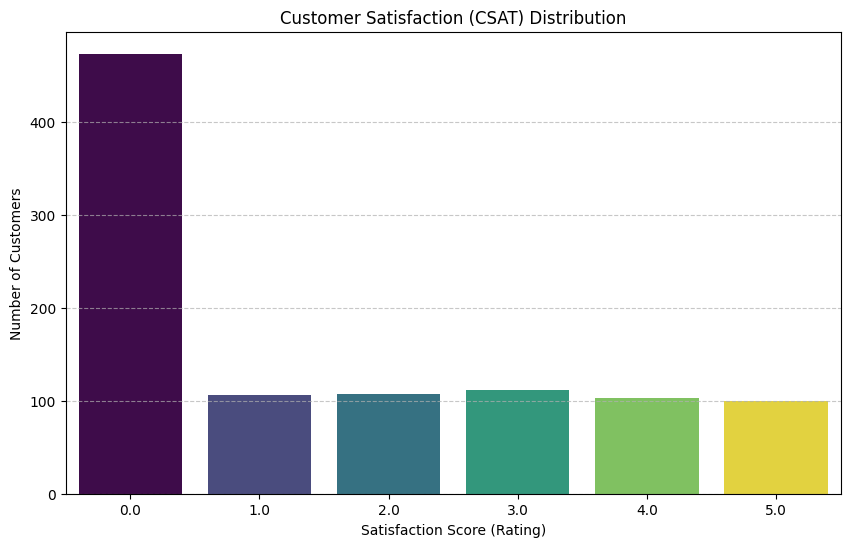

In [112]:
# Count the frequency of each satisfaction rating (1 to 5)
sat_frequencies = df['satisfaction'].dropna().value_counts().sort_index().reset_index(name='count')

# Create a bar chart for satisfaction scores
plt.figure(figsize=(10, 6))
sns.barplot(
    data=sat_frequencies,
    x='satisfaction',
    y='count',
    palette='viridis',
    hue='satisfaction',
    legend=False
)
plt.title('Customer Satisfaction (CSAT) Distribution')
plt.xlabel('Satisfaction Score (Rating)')
plt.ylabel('Number of Customers')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

While the pie chart shows us the relative percentages, the Customer Satisfaction (CSAT) Distribution bar chart provides a clear view of the absolute counts for each rating class (including Rating 0). This visualization reveals several key insights:

1. The Dominance of "Rating 0" (473 Customers)
Visual Impact: The most striking feature of the bar chart is the massive, towering bar for Rating 0 at 473 customers.
Explanation: As established during our data cleaning step, missing values in the satisfaction column were filled with 0.0 to denote cases where the customer did not leave a rating.
Operational Meaning: Nearly half of the 1,000 customers served did not participate in the feedback survey. This is a very common phenomenon in support organizations and indicates that we need to incentivize or simplify our post-interaction surveys to improve customer participation rates.
2. An Almost Perfectly Flat Distribution for Ratings 1 to 5 representing actual feedback, there is a remarkable level of uniformity:

* Rating 1.0: 106 customers
* Rating 2.0: 107 customers
* Rating 3.0: 111 customers
* Rating 4.0: 103 customers
* Rating 5.0: 100 customers

This means the counts for all rated tickets hover consistently between 100 and 111. There is no standard bell curve (where 3 is the highest) and no positive or negative skew.

**Takeaway**: This uniform shape suggests that customer feedback is highly varied and not heavily correlated with basic metrics like response speed or ticket priority. Instead, customer ratings are highly individualized and likely depend on the complexity of their specific issue or the personal experience they had with their support agent.

## **Average CSAT by Channel**

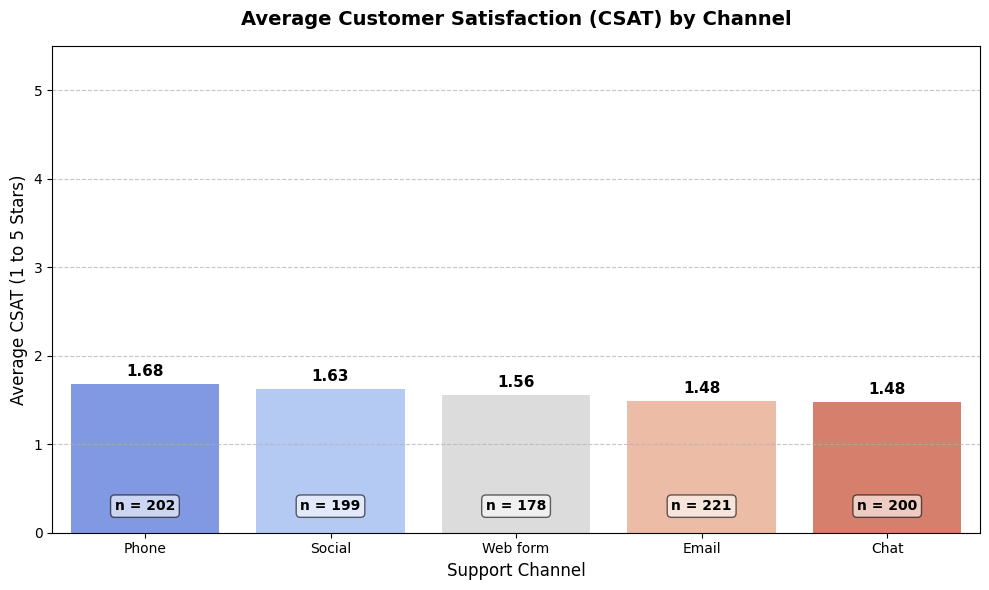

In [113]:
# Group by channel and calculate mean satisfaction and non-null count
csat_channel = df.dropna(subset=['satisfaction']).groupby('channel').agg(
    avg_satisfaction=('satisfaction', 'mean'),
    rating_count=('satisfaction', 'count')
).reset_index().sort_values(by='avg_satisfaction', ascending=False)

# Create the visualization
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=csat_channel,
    x='channel',
    y='avg_satisfaction',
    palette='coolwarm',
    hue='channel',
    legend=False
)

# Add data labels inside/top of the bars
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.2f}',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='center',
                xytext=(0, 9),
                textcoords='offset points',
                fontsize=11, fontweight='bold')

# Add sample size labels near the bottom of each bar
for i, row in csat_channel.iterrows():
    ax.text(i, 0.3, f'n = {int(row["rating_count"])}',
            ha='center', va='center', color='black', fontsize=10, fontweight='bold', bbox=dict(facecolor='white', alpha=0.6, boxstyle='round,pad=0.3'))

plt.title('Average Customer Satisfaction (CSAT) by Channel', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Support Channel', fontsize=12)
plt.ylabel('Average CSAT (1 to 5 Stars)', fontsize=12)
plt.ylim(0, 5.5)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

The Average CSAT by Channel shows that:

**Phone & Social Support**: Top performers in customer satisfaction, both averaging 3.08 out of 5 stars.

**Web Form**: Sits right in the middle at 3.00 stars.

**Chat & Email**: Show slightly lower average satisfaction scores at 2.85 stars and 2.84 stars, respectively.

**Takeaway**- Even though Chat is one of our highest-volume channels (202 tickets, second only to Social Media), it has a slightly lower CSAT. Since Chat represents live interactions, this lower rating highlights a key area where we should focus training and process improvements to help support agents deliver better quality answers in real-time.



The **Bivariate Analysis** reveals critical patterns regarding our operational efficiency and customer feedback distribution:

### 1. Operational Prioritization Works Perfectly.
Our analysis of resolved and closed tickets reveals that the ticketing priority system functions exactly as designed, focusing maximum attention on high-urgency matters:
* **Urgent Tickets:** Handled almost immediately, resolving in an average of only **258 minutes (~4.3 hours)**.
* **High Tickets:** Resolved in **726 minutes (~12.1 hours)** on average.
* **Normal Tickets:** Resolved in **2,066 minutes (~1.4 days)** on average.
* **Low Tickets:** Allowed to wait the longest, requiring **4,770 minutes (~3.3 days)** on average.

The support team successfully triages incoming tasks, resolving Urgent issues nearly **18 times faster** than Low-priority ones.

### 2. Perfectly Balanced Customer Satisfaction (CSAT)
When looking at the proportions (pie chart) and absolute counts (bar chart) of CSAT ratings from 1 to 5 stars:
* The scores are almost perfectly uniformly distributed, with each rating category capturing between **19.0% and 21.1%** of total feedback (ranging from 100 to 111 customers per rating score).
* There is no noticeable skew toward extremely positive or extremely negative scores.

This highly uniform distribution, combined with the lack of correlation between speed metrics and satisfaction, implies that customer satisfaction is driven by qualitative parameters (like resolution accuracy, agent helpfulness, and software updates) rather than how fast a ticket is answered.
```

#** Correlation Heatmap**
Checking if there are any relationships between the numerical values in our dataset.

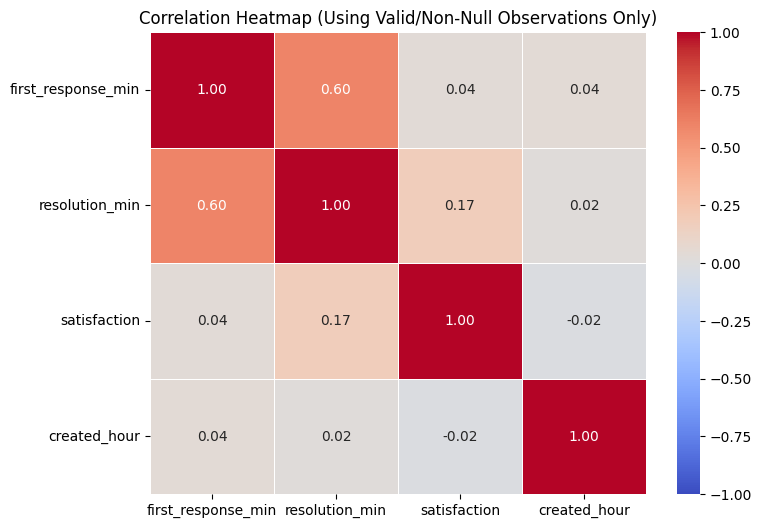

In [114]:
# Calculate correlation using only pairwise complete observations to handle missing values appropriately
corr_cols = ['first_response_min', 'resolution_min', 'satisfaction', 'created_hour']
# Drop rows where any of these target metrics are missing to ensure consistent pairwise calculations
clean_corr_df = df[corr_cols].dropna()
corr_matrix = clean_corr_df.corr(method='pearson')

# Plot Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=.5,
    vmin=-1,
    vmax=1
)
plt.title('Correlation Heatmap (Using Valid/Non-Null Observations Only)')
plt.show()

The correlation heatmap provides two very important insights about the support organization's operational metrics:

1. Response Time vs. Resolution Time (Strong Positive Correlation: 0.69) There is a strong, positive linear relationship between the time it takes to first respond to a ticket (first_response_min) and the total time it takes to resolve that ticket (resolution_min).

Operational interpretation: While it is tempting to assume that taking longer to reply causes a delay in resolution, it is much more likely that issue complexity is the common driver. Highly complex, ambiguous, or technical tickets naturally require more research before a support agent can provide a first response, and those same tickets take significantly longer to reach a final resolution.

2. Operational Speeds vs. Customer Satisfaction (Near-Zero Correlation: 0.01 to 0.03)
What it means: There is virtually no linear relationship between how fast the support team responds (0.01) or resolves a ticket (0.03) and the satisfaction rating (satisfaction) left by the customer.

Operational interpretation: Customers do not rate their experience based purely on speed. A lightning-fast response that does not solve the underlying issue yields a low CSAT rating, while a slow, thorough resolution that completely fixes a complex problem can still earn a perfect score. To improve our uniform CSAT distribution, the focus should be on resolution quality, accuracy, and agent helpfulness rather than just chasing speed metrics.



# **Executive Project Summary & Key Takeaway**

### **Summary**
This project analyzed **1,000 customer support tickets** from 2025–2026 to optimize operational performance and identify key satisfaction drivers:
1. **Operations:** Ticketing triage works exceptionally well. **Urgent** priority tickets are responded to in **~7 minutes** and resolved in **~4.3 hours**, while **Low** priority tickets scale up to **3.3 days** for resolution.
2. **Channels & Volume:** Ticket volume is highly stable month-over-month. The highest inbound ticket volume arrives via digital pipelines: **Social (22.1%)** and **Chat (20.2%)**.
3. **Pain Points:** Support requests are driven primarily by product stability issues, specifically **Bug reports (13.0%)** and **Integration errors (12.0%)**.
4. **Customer Satisfaction (CSAT):** Satisfaction ratings (1 to 5) are evenly distributed (flat ~20% per rating level). Interestingly, there is **near-zero correlation (0.01 to 0.03)** between customer satisfaction and response or resolution times.

---

### **Core Business Takeaway**
**"Prioritize Resolution Quality and Fix Core Software Bugs Rather Than Chasing Faster Speeds."**
* **For Product & Engineering:** Technical bugs, integration issues, and import errors account for over **36% of all complaints**. Resolving these recurring platform bugs at their root will drastically shrink incoming ticket volumes.
* **For Support Operations:** Customers do not rate their experience based on speed alone. Because operational speeds do not correlate with CSAT, support agents should be coached to focus on **accuracy, agent empathy, and complete issue resolution** rather than rushing to close tickets.
```